환경 클래스의 구조

In [15]:
import torch
import numpy as np
from FEA_Comp import fea_c
from VAE import VAE
from bc_options import *

class TopologyEnvironment:
    def __init__(self, vae_model, initial_topology):
        self.vae_model = vae_model; print("init")
        self.state = initial_topology; print("init")
        self.current_compliance = fea_c(64, 32, MTruss, 0, 2112, initial_topology); print("init")
    
    def reset(self):
        z = torch.randn(1, 2)
        initial_topology = self.vae_model.decoder(z).detach().numpy()
        self.state = initial_topology  # 초기 토폴로지를 무작위로 설정
        self.current_compliance = fea_c(64, 32, MTruss, 0, 2112, self.state)
        return self.state
    
    def step(self, action):
        # 현재 토폴로지를 잠재 벡터로 인코딩
        latent_vector = self.vae_model.encoder(self.state)
        
        # 잠재 벡터를 에이전트의 행동(action)으로 변형
        new_latent_vector = latent_vector + action
        
        # 새로운 잠재 벡터를 토폴로지로 디코딩
        new_topology = self.vae_model.decoder(new_latent_vector)
        
        # 새로운 토폴로지의 compliance 계산
        new_compliance = fea_c(64, 32, MTruss, 0, 2112, new_topology)
        
        # 보상 계산 (compliance가 낮을수록 보상이 큼)
        reward = self.current_compliance - new_compliance
        
        # 상태 업데이트
        self.state = new_topology
        self.current_compliance = new_compliance
        
        return self.state, reward


RL agent; MLP 모델

In [16]:
import torch.nn as nn
import torch.optim as optim
from torchrl.modules import MLP

class MLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, output_dim)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Actor-critic 모델을 위한 Value 함수와 Policy 함수 정의
class ActorCritic(nn.Module):
    def __init__(self, input_dim, action_dim):
        super(ActorCritic, self).__init__()
        self.policy = MLP(input_dim, action_dim)
        self.value = MLP(input_dim, 1)
        
    def forward(self, x):
        action_probs = self.policy(x)
        state_values = self.value(x)
        return action_probs, state_values


PPO

In [17]:
import torch
import torch.nn.functional as F

class PPO:
    def __init__(self, actor_critic, lr=3e-4, gamma=0.99, eps_clip=0.2, K_epochs=4):
        self.actor_critic = actor_critic
        self.optimizer = optim.Adam(actor_critic.parameters(), lr=lr)
        self.gamma = gamma
        self.eps_clip = eps_clip
        self.K_epochs = K_epochs
    
    def update(self, memory):
        # Memory에서 데이터를 추출
        state_arr, action_arr, reward_arr, old_log_probs_arr = memory.sample()
        
        # Advantage 계산
        state_values = self.actor_critic.value(state_arr)
        rewards = []
        discounted_reward = 0
        for reward in reversed(reward_arr):
            discounted_reward = reward + (self.gamma * discounted_reward)
            rewards.insert(0, discounted_reward)
        rewards = torch.tensor(rewards, dtype=torch.float32)
        advantages = rewards - state_values.detach()
        
        for _ in range(self.K_epochs):
            log_probs, state_values = self.actor_critic(state_arr)
            log_probs = log_probs.gather(1, action_arr)
            ratios = torch.exp(log_probs - old_log_probs_arr)
            
            surr1 = ratios * advantages
            surr2 = torch.clamp(ratios, 1 - self.eps_clip, 1 + self.eps_clip) * advantages
            
            loss = -torch.min(surr1, surr2) + F.mse_loss(state_values, rewards)
            
            self.optimizer.zero_grad()
            loss.mean().backward()
            self.optimizer.step()


학습 루프

working 1
working 2:
init
init


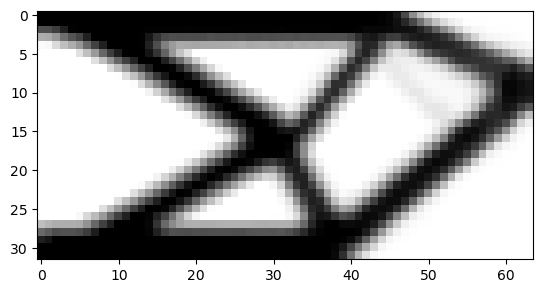

init
working 2
working 2
working 2
working 2
working 2
working 3


  0%|          | 0/1000 [00:00<?, ?it/s]

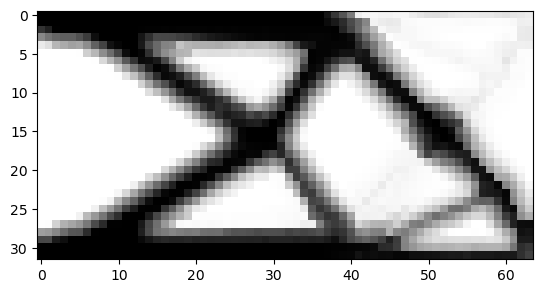

C:\Users\User\AppData\Local\Temp\ipykernel_9268\2272587064.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
  0%|          | 0/1000 [00:09<?, ?it/s]

0
1


RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x2048 and 2x64)

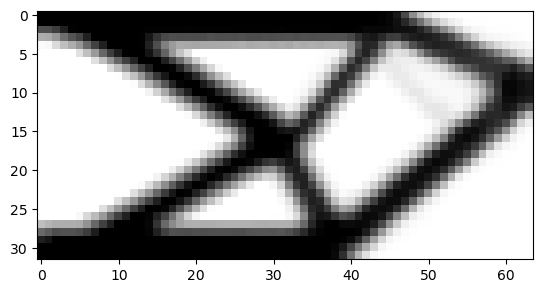

In [18]:
from torchrl.data import ReplayBuffer

from tqdm import tqdm

from matplotlib import colors
import matplotlib.pyplot as plt

# 초기화

print("working 1")

initial_topology = np.random.rand(64, 32)  # 초기 토폴로지

vae_model = VAE(x_dim=64*32, h_dim1= 512, h_dim2=256, z_dim=2)
vae_model.load_state_dict(torch.load('./vae_model_mtruss.pt', weights_only=True))

z = torch.randn(1, 2)
initial_topology = vae_model.decoder(z).detach().numpy()

print("working 2:")

env = TopologyEnvironment(vae_model, initial_topology=initial_topology); print("working 2")
actor_critic = ActorCritic(input_dim=2, action_dim=2); print("working 2")
ppo = PPO(actor_critic); print("working 2")
memory = ReplayBuffer(); print("working 2")
capacity=1000; print("working 2")

print("working 3")

# 학습 루프
num_episodes = 1000
for episode in tqdm(range(num_episodes)):
    state = env.reset()
    
    plt.ion() # Ensure that redrawing is possible
    fig,ax = plt.subplots()
    im = ax.imshow(-initial_topology.reshape((64,32)).T, cmap='gray',\
    interpolation='none',norm=colors.Normalize(vmin=-1,vmax=0))
    fig.show()

    change = 1; loop = 0
    print(loop)
    while change>0.01 and loop<20:
        loop += 1
        print(loop)
        action_probs, _ = actor_critic(torch.FloatTensor(state))
        action = torch.multinomial(action_probs, 1).item()
        
        new_state, reward = env.step(action)
        
        # Memory에 데이터 저장
        memory.add((state, action, reward, action_probs))
        
        change=np.linalg.norm(new_state.reshape(64*32,1)-state.reshape(64*32,1),np.inf)
        
        state = new_state

        im.set_array(-state.reshape((64,32)).T)
        fig.canvas.draw()
        

        # 메모리가 가득 차면 PPO 업데이트
        if len(memory) == capacity:
            ppo.update(memory)
            memory.clear()
